# MIX-seq Drug Screen: Cell Line Identity and Drug Responses

MIX-seq pools dozens of cancer cell lines, treats the pool with a drug, profiles the cells by single-cell RNA-seq, and assigns every cell back to its cell line from its SNPs ([McFarland et al. 2020](https://doi.org/10.1038/s41467-020-17440-w)). The pertpy paper ([Heumos et al. 2025](https://doi.org/10.1038/s41592-025-02909-7), Fig. 3) revisits this screen: it annotates the cell lines and drugs with public metadata, then models how each gene's response to dabrafenib, a BRAF inhibitor, depends on how sensitive each cell line is to the drug.

This tutorial explores the same screen interactively with linked UMAPs and Clustergrams. Instead of fitting a model up front, we first look at the biology that organizes the data, cell line identity, and then dig into the drug responses within it:

1. **Cell line identity:** what distinguishes the cell lines that organize the UMAP?
2. **Drug responses within one cell line:** which drugs change the same genes, and which genes are they?
3. **One drug across cell lines:** which cell lines respond to dabrafenib, and how?

**Data:** the 24-hour drug panel of the screen, 13 drugs and DMSO controls across about 170 cancer cell lines, with every gene detected in at least 3 cells. The data were released by McFarland et al. on [figshare](https://doi.org/10.6084/m9.figshare.10298696) under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/) and harmonized by [scPerturb](https://doi.org/10.5281/zenodo.7041849) (Peidli et al. 2024; CC BY 4.0). The [pre-process notebook](https://huggingface.co/datasets/broadinstitute/Celldega_Supporting_Data/blob/main/McFarland_2020/McFarland_2020_Pre-process.ipynb) on Hugging Face documents how we subset and packaged them; the DegaFiles for the Landscapes are in the [Celldega_McFarland_2020](https://github.com/broadinstitute/Celldega_McFarland_2020) GitHub repository.

## Setup

Use Python 3.11 or 3.12 and Celldega 0.27.0 or later:

```python
%pip install "celldega[scanpy]>=0.27.0" igraph ipykernel
```

The notebook downloads a 680 MB AnnData file once, and the Landscapes read DegaFiles from GitHub. Enrich queries the public Enrichr service. All three need an internet connection.

In [1]:
from pathlib import Path
import shutil
from urllib.request import Request, urlopen

import anndata as ad
import celldega as dega
import numpy as np
import pandas as pd
import scanpy as sc

sc.settings.verbosity = 1

In [2]:
DATA_URL = "https://huggingface.co/datasets/broadinstitute/Celldega_Supporting_Data/resolve/main/McFarland_2020"
DEGA_FILES_URL = "https://raw.githubusercontent.com/broadinstitute/Celldega_McFarland_2020/main"

# Reuse the repository's notebook data directory when running from a checkout;
# otherwise cache the download beside the notebook.
working_dir = Path.cwd().resolve()
project_root = next(
    (
        directory
        for directory in (working_dir, *working_dir.parents)
        if (directory / "pyproject.toml").is_file() and (directory / "notebooks").is_dir()
    ),
    None,
)
data_dir = (project_root / "notebooks" if project_root else working_dir) / "data" / "mcfarland_2020"
data_dir.mkdir(parents=True, exist_ok=True)

h5ad_path = data_dir / "McFarland_2020_24h_drug_panel.h5ad"
if not h5ad_path.is_file():
    partial = h5ad_path.with_suffix(".h5ad.part")
    request = Request(f"{DATA_URL}/{h5ad_path.name}", headers={"User-Agent": "celldega-example-notebook"})
    try:
        with urlopen(request, timeout=600) as response, partial.open("wb") as output:
            shutil.copyfileobj(response, output, length=1024 * 1024)
        partial.replace(h5ad_path)
    except Exception:
        partial.unlink(missing_ok=True)
        raise

adata = ad.read_h5ad(h5ad_path)
print(f"{adata.n_obs:,} cells, {adata.obs['cell_line'].nunique()} cell lines, {adata.n_vars:,} genes")
adata.obs[["perturbation", "mechanism"]].value_counts().rename("cells").to_frame()

86,907 cells, 169 cell lines, 27,800 genes


,,cells
perturbation,mechanism,
Trametinib,MEK inhibitor,16101
control,Control (DMSO),13150
Dabrafenib,BRAF inhibitor,10867
BRD3379,Unknown,9229
Navitoclax,BCL-2/BCL-xL inhibitor,8432
AZD5591,MCL1 inhibitor,6074
JQ1,BET inhibitor,4658
Everolimus,mTOR inhibitor,3176
Prexasertib,CHK1 inhibitor,3171


The precomputed UMAP groups cells by cancer type and cell line, not by drug or mechanism of action:

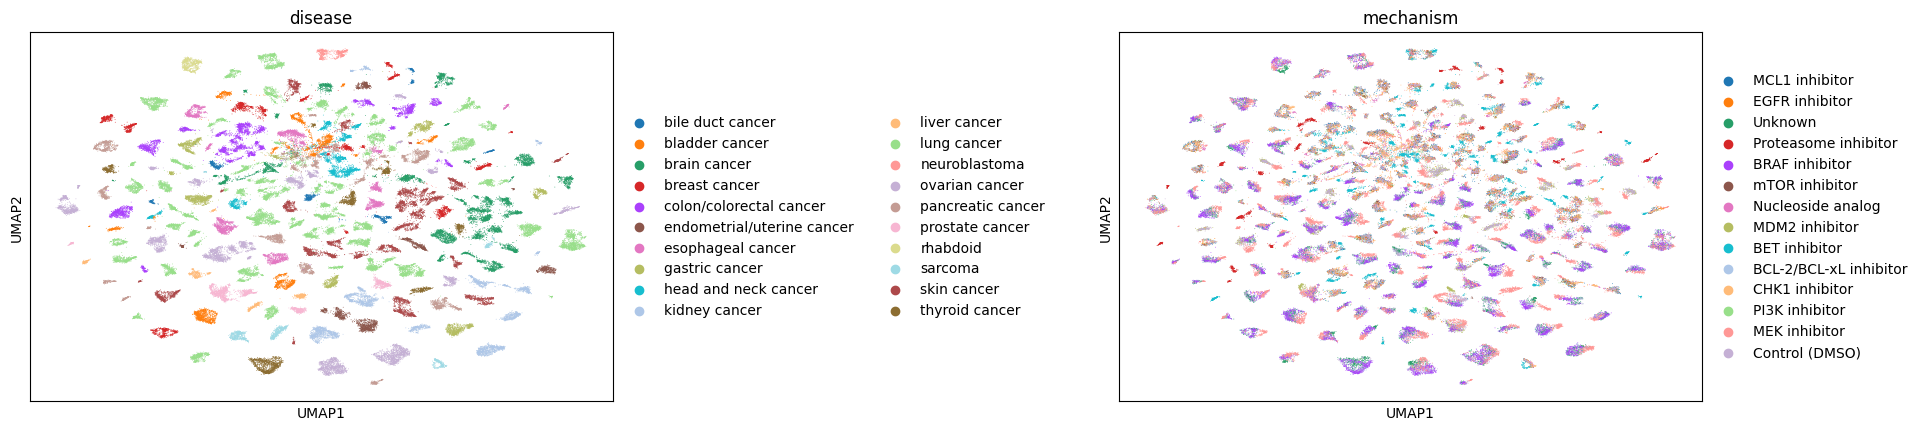

In [3]:
sc.pl.umap(adata, color=["disease", "mechanism"], wspace=0.7)

## Pseudobulk profiles

Most comparisons below are between groups of cells, so we sum the counts of each group into a pseudobulk profile and convert it to log2 counts per million (CPM), keeping profiles built from at least 20 cells. A drug's response in a cell line is the log2 fold change of its profile over the DMSO profile of the same cell line from the same experiment group: the screen ran its drugs in separate experiments, each with its own controls (see the pre-process notebook).

In [4]:
MIN_CELLS = 20


def log_cpm_profiles(cells, by):
    # Sum each group's counts into a pseudobulk profile and convert it to log2 CPM.
    profiles = sc.get.aggregate(cells, by=by, func="sum")
    profiles.X = profiles.layers.pop("sum")
    sizes = cells.obs.groupby(by, observed=True).size().rename("n_cells").reset_index()
    profiles.obs = profiles.obs.merge(sizes, on=by, how="left").set_index(profiles.obs_names)
    profiles = profiles[profiles.obs["n_cells"] >= MIN_CELLS].copy()
    sc.pp.normalize_total(profiles, target_sum=1e6)
    sc.pp.log1p(profiles, base=2)
    return profiles


def expressed_genes(profiles, min_cpm=20):
    # Genes averaging at least `min_cpm` counts per million across log2 CPM profiles.
    return profiles.columns[(np.exp2(profiles) - 1).mean() >= min_cpm]


groups = ["cell_line", "experiment", "perturbation"]
profiles = log_cpm_profiles(adata, groups)
log_cpm = profiles.to_df()
log_cpm.index = pd.MultiIndex.from_frame(profiles.obs[groups].astype(str))

control = log_cpm.xs("control", level="perturbation")
treated = log_cpm.drop(index="control", level="perturbation")
treated = treated[treated.index.droplevel("perturbation").isin(control.index)]
responses = treated - control.loc[treated.index.droplevel("perturbation")].to_numpy()

line_disease = adata.obs.groupby("cell_line", observed=True)["disease"].first().astype(str)
mechanism_of = adata.obs.groupby("perturbation", observed=True)["mechanism"].first().astype(str)
print(f"{len(responses):,} drug responses in {responses.index.get_level_values('cell_line').nunique()} cell lines")

936 drug responses in 159 cell lines


## Level 1: Cell line identity

Start with the biology that organizes the UMAP. Each column of the Clustergram below is a cell line, summarized by its DMSO-treated control cells and colored by cancer type. Rows are the 500 genes that vary most across cell lines, z-scored across cell lines.

The Landscape shows every cell in the UMAP, colored by cell line. Click a cell line column to highlight its cells, click a gene row to color the UMAP by that gene, and select a branch of the gene dendrogram to send it to Enrich, which starts on the ARCHS4 tissue library to suggest which tissue a gene program comes from.

In [5]:
controls = log_cpm_profiles(adata[adata.obs["perturbation"] == "control"], ["cell_line"])
controls.obs_names = controls.obs["cell_line"].astype(str).to_numpy()
controls.obs = pd.DataFrame(
    {"disease": pd.Categorical(line_disease[controls.obs_names])}, index=controls.obs_names
)
sc.pp.highly_variable_genes(controls, n_top_genes=500)
line_signatures = controls[:, controls.var["highly_variable"]].copy()

# Columns select cells by the Landscape's coloring attribute (cell_line below).
mat_lines = dega.clust.Matrix(
    line_signatures,
    col_attr=["disease"],
    col_entity={"entity": "cell", "attr": "cluster"},
    name="mcfarland_cell_lines",
)
mat_lines.norm("row", by="zscore")
mat_lines.cluster()
cgm_lines = dega.viz.Clustergram(matrix=mat_lines, width=650, height=600)

landscape_lines = dega.viz.Landscape(
    technology="Chromium",
    base_url=DEGA_FILES_URL,
    adata=adata,
    cell_attr=["cell_line"],
    cluster_attr="cell_line",
    transform=np.eye(3),
    ini_zoom=-4.5,
    ini_x=5000,
    ini_y=5000,
)
linked_lines = dega.viz.spatial_clustergram(
    landscape_lines,
    cgm_lines,
    width="500px",
    height="800px",
    enrich=True,
    enrich_kwargs={"inst_lib": "ARCHS4_Tissues"},
)

In [6]:
linked_lines

The cell lines fall into a few large groups that cut across cancer types. One branch of columns shares epithelial genes such as KRT19, SFN, S100A14, AGR2, and CEACAM6, and holds the colorectal, esophageal, and most breast cancer lines. Another shares mesenchymal genes such as COL6A2, COL6A3, SERPINE1, LGALS1, and THY1, and holds the brain cancer lines and the melanomas, which also express pigment-cell genes such as PMEL and MLANA. Smaller branches gather kidney, liver, and ovarian lines (FXYD2, CDH6, CLDN2, AGT) and neuroendocrine lines (ASCL1, CHGA, NEUROD1): small cell lung cancer lines such as DMS273 and NCIH1048, a neuroblastoma, and a pancreatic neuroendocrine line. Lung cancer lines turn up in nearly every branch, a reminder that "lung cancer" spans several distinct lineages.

Two of the most variable genes have nothing to do with lineage: XIST, expressed from the inactive X chromosome, and RPS4Y1, on the Y chromosome. RPS4Y1 is high only in male lines and XIST almost only in female lines, while many lines have lost XIST expression or the Y chromosome, which is common in cancer cell lines.

Click the PMEL row to light up the melanoma cells in the UMAP, or select the epithelial gene branch to see which tissues Enrich matches it to.

In [7]:
lineage_branches = mat_lines.cut_tree(axis="col", n_clusters=6)
branch_table = pd.crosstab(controls.obs.loc[lineage_branches.index, "disease"], lineage_branches)
branch_table[branch_table.sum(axis=1) >= 5]

cluster,1,2,3,4,5,6
disease,,,,,,
bladder cancer,4,0,0,1,0,2
brain cancer,0,0,0,0,0,15
breast cancer,6,0,0,0,0,2
colon/colorectal cancer,10,0,0,0,0,0
esophageal cancer,6,0,0,0,0,0
gastric cancer,2,0,0,1,1,2
kidney cancer,0,0,0,5,0,0
lung cancer,13,6,4,4,0,12
ovarian cancer,4,2,0,5,0,0


Cutting the cell line dendrogram into six branches makes these groups concrete: all 10 colorectal and all 6 esophageal lines fall in the epithelial branch, all 15 brain cancer lines and 14 of the 15 melanomas in the mesenchymal branch, and all 5 kidney lines in the kidney, liver, and ovarian branch, while the lung cancer lines spread across five branches.

## Level 2: Drug responses within one cell line

Cell line identity dominates the global UMAP and hides the drug responses. Within a single cell line the baseline is shared, so differences between drugs come forward. We take the cell line profiled with the most drugs, compute a UMAP of its cells alone, and cluster its drug responses.

With all DMSO cells pooled as controls, this cell line's drugs cluster by experiment rather than by mechanism, which is why each drug is compared with controls from its own experiment group. Trametinib was run in both groups, so it appears twice, an internal replicate.

In [8]:
treated_lines = responses.index.get_level_values("cell_line")
n_drugs = pd.Series(responses.index.get_level_values("perturbation")).groupby(treated_lines.to_numpy()).nunique()
line = n_drugs.idxmax()
print(f"{line} ({line_disease[line]}): {n_drugs[line]} drugs")

# Cells of this line's profiled conditions, labeled like the Clustergram columns.
line_groups = log_cpm.loc[line].index
cell_groups = pd.MultiIndex.from_frame(adata.obs[["experiment", "perturbation"]].astype(str))
line_cells = adata[(adata.obs["cell_line"] == line).to_numpy() & cell_groups.isin(line_groups)].copy()
n_experiments = line_groups.to_frame(index=False).groupby("perturbation").size()


def condition(experiment, drug):
    return f"{drug} ({experiment})" if n_experiments[drug] > 1 else drug


line_cells.obs["condition"] = pd.Categorical(
    [condition(*group) for group in line_cells.obs[["experiment", "perturbation"]].astype(str).itertuples(index=False)]
)
sc.pp.normalize_total(line_cells, target_sum=1e4)
sc.pp.log1p(line_cells)
sc.pp.highly_variable_genes(line_cells, n_top_genes=2000)
sc.tl.pca(line_cells, mask_var="highly_variable", random_state=0)
sc.pp.neighbors(line_cells, n_neighbors=15, n_pcs=20, random_state=0)
sc.tl.umap(line_cells, random_state=0)

line_responses = responses.loc[line]
conditions = [condition(*group) for group in line_responses.index]
drug_responses = ad.AnnData(
    line_responses[expressed_genes(log_cpm.loc[line])].set_axis(conditions).astype("float32")
)
drug_responses.obs = pd.DataFrame(
    {
        "mechanism": pd.Categorical(line_responses.index.get_level_values("perturbation").map(mechanism_of)),
        "experiment": pd.Categorical(line_responses.index.get_level_values("experiment")),
    },
    index=drug_responses.obs_names,
)

mat_drugs = dega.clust.Matrix(
    drug_responses,
    col_attr=["mechanism", "experiment"],
    col_entity={"entity": "cell", "attr": "cluster"},
    name="mcfarland_drug_responses",
)
mat_drugs.filter("row", by="var", num=200)
mat_drugs.cluster()
cgm_drugs = dega.viz.Clustergram(matrix=mat_drugs, width=450, height=600)

landscape_drugs = dega.viz.Landscape(
    technology="Chromium",
    base_url=DEGA_FILES_URL,
    adata=line_cells,
    cell_attr=["condition", "experiment"],
    cluster_attr="condition",
    transform=np.eye(3),
    ini_zoom=-4.5,
    ini_x=5000,
    ini_y=5000,
)
linked_drugs = dega.viz.spatial_clustergram(
    landscape_drugs,
    cgm_drugs,
    width="550px",
    height="800px",
    enrich=True,
    enrich_kwargs={"inst_lib": "GO_Biological_Process_2025"},
)

COLO680N (esophageal cancer): 13 drugs


In [9]:
linked_drugs

Columns are drugs, colored by mechanism of action and experiment group. Rows are the 200 genes whose response varies most across drugs, red for up and blue for down relative to DMSO. Click a drug to highlight its cells in this cell line's UMAP.

COLO680N, an esophageal cancer line, was profiled with all 13 drugs:

- **The trametinib replicates agree.** The two trametinib columns, from different experiments, are each other's closest match and share a branch with afatinib. Afatinib blocks EGFR and trametinib blocks MEK, which EGFR signals through, so both shut down MAPK targets such as DUSP6, ETV4, and FOSL1 and induce the squamous differentiation gene KRT13 and the death ligand TNFSF10 (TRAIL). Taselisib, which blocks the PI3K branch of EGFR signaling, shares the TNFSF10 increase but not the MAPK-target decrease.
- **Bortezomib** has the strongest response. Inhibiting the proteasome makes misfolded proteins pile up, and heat shock genes such as HSPA6 (more than 1,000-fold) and HSPA1A shoot up.
- **JQ1**, a BET bromodomain inhibitor, induces HEXIM1, a standard marker of BET inhibition, along with replication-dependent histone genes. JQ1 and bortezomib both shut down proliferation genes such as TOP2A and MKI67.
- **Dabrafenib, navitoclax, and BRD3379** barely change this cell line.

Two patterns follow the experiment bar rather than the drugs. Interferon-stimulated genes (IFIT2, IFIT3, OASL) rise with every experiment 10 drug, including trametinib, but not with trametinib in experiments 1 and 3. And four genes (EEF1A2, ZFPM1, NANOS1, TAGLN) drop with the three experiment 3 drugs, whose controls are pooled with those of experiment 1. Matched controls remove most of the batch effect, and the experiment bar makes what remains easy to spot.

## Level 3: One drug across cell lines

Finally, follow one drug across the cell lines it was tested in, as the pertpy paper does for dabrafenib. Dabrafenib inhibits the mutant BRAF V600E kinase that drives MAPK signaling in many melanomas, so its effect should depend on each cell line's genetics. For each cell line with at least 20 treated cells and 20 matched control cells, compute the response as above and cluster the cell lines by their responses. Enrich starts on Gene Ontology biological processes.

In [10]:
drug = "Dabrafenib"
drug_responses_by_line = responses.xs(drug, level="perturbation")
tested = drug_responses_by_line.index
genes = expressed_genes(pd.concat([log_cpm.xs(drug, level="perturbation").loc[tested], control.loc[tested]]))
all_responses = drug_responses_by_line.droplevel("experiment")
print(f"{drug}: {len(all_responses)} cell lines")

dabrafenib_responses = ad.AnnData(all_responses[genes].astype("float32"))
dabrafenib_responses.obs["disease"] = pd.Categorical(dabrafenib_responses.obs_names.map(line_disease))

mat_dabrafenib = dega.clust.Matrix(dabrafenib_responses, col_attr=["disease"], name="mcfarland_dabrafenib")
mat_dabrafenib.filter("row", by="var", num=200)
mat_dabrafenib.cluster()
cgm_dabrafenib = dega.viz.Clustergram(matrix=mat_dabrafenib, width=490, height=600)

dabrafenib_enrich = dega.viz.clustergram_enrich(cgm_dabrafenib)
enrich = dabrafenib_enrich.children[1]
enrich.inst_lib = "GO_Biological_Process_2025"
# Match the Clustergram's full height, which includes its control panel.
enrich.height = 800

Dabrafenib: 94 cell lines


In [11]:
dabrafenib_enrich

The first split of the cell line dendrogram separates nine cell lines, six of them melanomas, from the other 85. In these lines dabrafenib shuts down a branch of about 70 genes that barely changes elsewhere: MAPK targets such as ETV4, DUSP5, and EGR1, along with secreted factors such as IL8, LIF, and CCL2. BRAF V600E, the mutation dabrafenib targets, drives about half of melanomas, and these are the lines in which the drug blocks MAPK signaling. Select this gene branch to see which processes Enrich finds. The same melanoma lines also raise melanocyte differentiation genes such as DCT and MITF, consistent with reports that BRAF inhibition increases melanocytic antigen expression in melanoma (Frederick et al. 2013).

To check the MAPK reading, the table below averages the response of six canonical MAPK targets from the MAPK Pathway Activity Score (Wagle et al. 2018) in each cell line, listing the eight lines with the largest decrease and the five with the largest increase.

In [12]:
MAPK_TARGETS = ["DUSP6", "SPRY4", "ETV4", "ETV5", "SPRY2", "PHLDA1"]
mapk = all_responses[[gene for gene in MAPK_TARGETS if gene in all_responses.columns]]
mapk = mapk.assign(mean=mapk.mean(axis=1), disease=mapk.index.map(line_disease)).sort_values("mean")
pd.concat([mapk.head(8), mapk.tail(5)]).round(2)

,DUSP6,SPRY4,ETV4,ETV5,SPRY2,PHLDA1,mean,disease
cell_line,,,,,,,,
SKMEL24,-2.69,-3.41,-4.13,-1.50,-1.42,-1.71,-2.48,skin cancer
A375,-2.43,-2.66,-3.59,-2.17,-1.12,-1.04,-2.17,skin cancer
MALME3M,-1.94,-0.92,-4.50,-1.31,-2.02,-2.18,-2.15,skin cancer
MDAMB435S,-1.07,-1.95,-2.66,-1.80,-0.75,-1.39,-1.60,skin cancer
UACC257,-0.73,-1.06,-2.36,-0.79,-0.57,-1.14,-1.11,skin cancer
IGR1,-0.33,-0.20,-2.78,-0.95,-0.54,-1.14,-0.99,skin cancer
22RV1,-0.01,-0.39,-0.63,-0.37,-1.07,-1.66,-0.69,prostate cancer
8505C,-0.25,-0.79,-0.98,0.08,-0.54,-0.85,-0.56,thyroid cancer
CAOV3,1.10,1.36,-0.01,0.25,-0.05,0.87,0.59,ovarian cancer


The six strongest decreases are all melanomas, including A375, a standard BRAF V600E melanoma model. In most of the other lines, the MAPK targets rise slightly instead: 78 of the 94 lines have a positive mean change. This matches the paradoxical effect of RAF inhibitors in cells without a BRAF mutation, where the drug binds one RAF protein of a dimer and activates its partner, increasing MAPK signaling (Poulikakos et al. 2010; Hatzivassiliou et al. 2010).

The genes the pertpy paper highlights fit this picture. ETV4 follows the MAPK targets almost exactly (r = 0.92 across cell lines) and drops sharply in the melanomas, as do CDKN2D and MYEOV. UBALD2, the paper's example of a response that does not depend on drug sensitivity, rises in 90% of the cell lines but not in the melanomas, and it tracks the MAPK targets (r = 0.62), so in this view its increase looks like part of the paradoxical MAPK activation. Testing such hypotheses against drug sensitivity data, as the pertpy paper does, is a natural next step.

## Next steps

- Repeat Level 2 for another cell line, or Level 3 for another drug. Idasanutlin, an MDM2 inhibitor, is a good contrast: its response depends on whether a cell line's p53 pathway is intact.
- Compare the responses with drug sensitivity measured in the same cell lines, as McFarland et al. and the pertpy paper do, to separate responses tied to cell death from those that are not.

## References

- McFarland JM, Paolella BR, Warren A, et al. Multiplexed single-cell transcriptional response profiling to define cancer vulnerabilities and therapeutic mechanism of action. *Nature Communications* 11, 4296 (2020). https://doi.org/10.1038/s41467-020-17440-w
- Cancer Data Science (Broad Institute). MIX-seq data. figshare (2020). https://doi.org/10.6084/m9.figshare.10298696 (CC BY 4.0)
- Peidli S, Green TD, Shen C, et al. scPerturb: harmonized single-cell perturbation data. *Nature Methods* 21, 531–540 (2024). https://doi.org/10.1038/s41592-023-02144-y; data: https://doi.org/10.5281/zenodo.7041849 (CC BY 4.0)
- Heumos L, Ji Y, May L, et al. Pertpy: an end-to-end framework for perturbation analysis. *Nature Methods* 23, 350–359 (2026). https://doi.org/10.1038/s41592-025-02909-7
- Poulikakos PI, Zhang C, Bollag G, Shokat KM, Rosen N. RAF inhibitors transactivate RAF dimers and ERK signalling in cells with wild-type BRAF. *Nature* 464, 427–430 (2010). https://doi.org/10.1038/nature08902
- Hatzivassiliou G, Song K, Yen I, et al. RAF inhibitors prime wild-type RAF to activate the MAPK pathway and enhance growth. *Nature* 464, 431–435 (2010). https://doi.org/10.1038/nature08833
- Wagle MC, Kirouac D, Klijn C, et al. A transcriptional MAPK Pathway Activity Score (MPAS) is a clinically relevant biomarker in multiple cancer types. *npj Precision Oncology* 2, 7 (2018). https://doi.org/10.1038/s41698-018-0051-4
- Frederick DT, Piris A, Cogdill AP, et al. BRAF inhibition is associated with enhanced melanoma antigen expression and a more favorable tumor microenvironment in patients with metastatic melanoma. *Clinical Cancer Research* 19, 1225–1231 (2013). https://doi.org/10.1158/1078-0432.CCR-12-1630